# Phase 6 — Data Quality

**Objectifs:**
- [x] Data Quality Rules
- [x] Unit Tests
- [x] Quality Reports
- [x] Error Handling

**Livrable:** Data Quality Framework

**Objectif:** vérifier **automatiquement** à chaque exécution que les données Silver / Gold respectent les règles métier, **historiser** les résultats et **bloquer** le pipeline si une règle critique échoue.

Le framework est dans `lakehouse_transforms.py`: `build_dq_rules()`, `run_dq_checks()`, `assert_no_critical_failures()`.

## 0. Setup

In [1]:
from lakehouse_config import *
from lakehouse_transforms import *
spark = get_spark()
setup_schemas(spark)

from pyspark.sql import functions as F
from pyspark.sql.types import *
import pandas as pd
import uuid

## 1. Data Quality Rules

Chaque règle = **table + condition SQL qui doit être vraie** pour chaque ligne + **sévérité**:
- `critical` → bloque le pipeline (donnée inutilisable).
- `warning` → signalé dans le rapport, mais n'arrête rien.

Type `unique` → vérifie l'unicité d'une colonne (clé).

In [2]:
rules = build_dq_rules(T_SILVER_TRIPS, T_SILVER_ZONES, T_GOLD_DAILY_KPIS)
pd.DataFrame(rules)[["table", "rule", "severity", "type", "column", "condition"]].fillna("")

,table,rule,severity,type,column,condition
0,workspace.silver.yellow_trips,trip_id_unique,critical,unique,trip_id,
1,workspace.silver.yellow_trips,trip_id_not_null,critical,,,trip_id IS NOT NULL
2,workspace.silver.yellow_trips,positive_duration,critical,,,trip_duration_min > 0
3,workspace.silver.yellow_trips,positive_distance,critical,,,trip_distance > 0
4,workspace.silver.yellow_trips,non_negative_total,critical,,,total_amount >= 0
5,workspace.silver.yellow_trips,valid_location,critical,,,pu_location_id BETWEEN 1 AND 265 AND do_locati...
6,workspace.silver.yellow_trips,valid_payment_type,warning,,,payment_type BETWEEN 0 AND 6
7,workspace.silver.yellow_trips,reasonable_passengers,warning,,,passenger_count BETWEEN 1 AND 6
8,workspace.silver.yellow_trips,tip_le_3x_fare,warning,,,"tip_amount <= GREATEST(fare_amount, 1) * 3"
9,workspace.silver.taxi_zones,location_id_unique,critical,unique,location_id,


## 2. Unit Tests
On teste les fonctions sur de **petits DataFrames construits à la main**, dont on connaît le résultat attendu. (Les mêmes tests existent en version `pytest` dans `tests/` — Phase 10.)

In [3]:
from datetime import datetime
from decimal import Decimal

test_results = []

def unit_test(name):
    def deco(fn):
        try:
            fn(); test_results.append((name, "PASS", ""))
        except AssertionError as e:
            test_results.append((name, "FAIL", str(e)))
        except Exception as e:
            test_results.append((name, "ERROR", f"{type(e).__name__}: {str(e)[:120]}"))
        return fn
    return deco


def make_silver_like(rows):
    schema = ("pickup_datetime timestamp, dropoff_datetime timestamp, trip_distance double, "
              "fare_amount decimal(10,2), total_amount decimal(10,2), pu_location_id int, do_location_id int")
    return spark.createDataFrame(rows, schema)


t0, t1 = datetime(2024, 1, 15, 10, 0), datetime(2024, 1, 15, 10, 20)

In [4]:
@unit_test("add_reject_reason: ligne valide -> motif vide")
def _():
    df = make_silver_like([(t0, t1, 2.5, Decimal("12.00"), Decimal("15.00"), 10, 20)])
    assert add_reject_reason(df).collect()[0].reject_reason == ""


@unit_test("add_reject_reason: distance 0 + montant negatif -> 2 motifs")
def _():
    df = make_silver_like([(t0, t1, 0.0, Decimal("-5.00"), Decimal("-5.00"), 10, 20)])
    reasons = set(add_reject_reason(df).collect()[0].reject_reason.split("; "))
    assert reasons == {"non_positive_distance", "negative_amount"}, reasons


@unit_test("add_reject_reason: dropoff avant pickup -> non_positive_duration")
def _():
    df = make_silver_like([(t1, t0, 2.0, Decimal("10.00"), Decimal("12.00"), 10, 20)])
    assert "non_positive_duration" in add_reject_reason(df).collect()[0].reject_reason


@unit_test("add_reject_reason: zone 300 -> invalid_location")
def _():
    df = make_silver_like([(t0, t1, 2.0, Decimal("10.00"), Decimal("12.00"), 300, 20)])
    assert "invalid_location" in add_reject_reason(df).collect()[0].reject_reason


@unit_test("handle_nulls: passenger_count null -> 1 + flag")
def _():
    df = spark.createDataFrame([(None, None, None, None, None)],
        "passenger_count int, ratecode_id int, store_and_fwd_flag string, "
        "congestion_surcharge decimal(10,2), airport_fee decimal(10,2)")
    r = handle_nulls(df).collect()[0]
    assert (r.passenger_count, r.passenger_count_imputed, r.ratecode_id, r.store_and_fwd_flag) == (1, True, 99, "N"), r


@unit_test("add_trip_id: deterministe et sensible aux valeurs")
def _():
    cols = "vendor_id int, pickup_datetime timestamp, dropoff_datetime timestamp, pu_location_id int, " \
           "do_location_id int, trip_distance double, total_amount decimal(10,2), passenger_count int"
    df = spark.createDataFrame([(1, t0, t1, 10, 20, 2.0, Decimal("12.00"), 1)] * 2 +
                               [(1, t0, t1, 10, 20, 2.0, Decimal("13.00"), 1)], cols)
    ids = [r.trip_id for r in add_trip_id(df).collect()]
    assert ids[0] == ids[1] and ids[0] != ids[2] and len(ids[0]) == 64


@unit_test("clean_zones: 'N/A' -> 'Unknown'")
def _():
    df = spark.createDataFrame([(264, "Unknown", "N/A", "N/A")], "LocationID int, Borough string, Zone string, service_zone string")
    r = clean_zones(df).collect()[0]
    assert (r.borough, r.zone, r.service_zone) == ("Unknown", "Unknown", "Unknown"), r


@unit_test("evaluate_rules: detecte doublons et violations")
def _():
    df = spark.createDataFrame([(1, 5.0), (1, -1.0), (2, 3.0)], "id int, amount double")
    res = evaluate_rules(df, [
        {"table": "t", "rule": "id_unique", "type": "unique", "column": "id", "severity": "critical"},
        {"table": "t", "rule": "amount_pos", "condition": "amount > 0", "severity": "critical"},
    ])
    assert [(r["failed_rows"], r["status"]) for r in res] == [(1, "FAIL"), (1, "FAIL")], res


pd.DataFrame(test_results, columns=["test", "statut", "detail"])

,test,statut,detail
0,add_reject_reason: ligne valide -> motif vide,PASS,
1,add_reject_reason: distance 0 + montant negati...,PASS,
2,add_reject_reason: dropoff avant pickup -> non...,PASS,
3,add_reject_reason: zone 300 -> invalid_location,PASS,
4,handle_nulls: passenger_count null -> 1 + flag,PASS,
5,add_trip_id: deterministe et sensible aux valeurs,PASS,
6,clean_zones: 'N/A' -> 'Unknown',PASS,
7,evaluate_rules: detecte doublons et violations,PASS,


In [5]:
assert all(s == "PASS" for _, s, _ in test_results), "Des tests unitaires ont echoue"
print(f"{len(test_results)} / {len(test_results)} tests unitaires OK")

8 / 8 tests unitaires OK


## 3. Quality Reports
### 3.1 Exécution des règles et historisation

In [6]:
run_id = str(uuid.uuid4())
dq_results = run_dq_checks(spark, rules, run_id)

dq_results.write.format("delta").mode("append").saveAsTable(T_DQ_RESULTS)
print("run_id:", run_id)
dq_results.drop("run_id", "run_ts").toPandas()

run_id: 69a5fe94-b911-42c8-8176-b78df38ebf2c


,table_name,rule_name,severity,total_rows,failed_rows,pass_rate,status
0,workspace.silver.yellow_trips,trip_id_unique,critical,5771620,0,100.0000,PASS
1,workspace.silver.yellow_trips,trip_id_not_null,critical,5771620,0,100.0000,PASS
2,workspace.silver.yellow_trips,positive_duration,critical,5771620,0,100.0000,PASS
3,workspace.silver.yellow_trips,positive_distance,critical,5771620,0,100.0000,PASS
4,workspace.silver.yellow_trips,non_negative_total,critical,5771620,0,100.0000,PASS
5,workspace.silver.yellow_trips,valid_location,critical,5771620,0,100.0000,PASS
6,workspace.silver.yellow_trips,valid_payment_type,warning,5771620,0,100.0000,PASS
7,workspace.silver.yellow_trips,reasonable_passengers,warning,5771620,63672,98.8968,FAIL
8,workspace.silver.yellow_trips,tip_le_3x_fare,warning,5771620,704,99.9878,FAIL
9,workspace.silver.taxi_zones,location_id_unique,critical,265,0,100.0000,PASS


### 3.2 Rapport de synthèse

In [7]:
spark.sql(f"""
SELECT table_name,
       COUNT(*)                                   AS regles,
       SUM(CASE WHEN status = 'PASS' THEN 1 END)  AS pass,
       SUM(CASE WHEN status <> 'PASS' AND severity = 'warning'  THEN 1 ELSE 0 END) AS warnings,
       SUM(CASE WHEN status <> 'PASS' AND severity = 'critical' THEN 1 ELSE 0 END) AS critical_failures,
       ROUND(AVG(pass_rate), 3)                   AS pass_rate_moyen
FROM {T_DQ_RESULTS}
WHERE run_id = '{run_id}'
GROUP BY table_name
""").show(truncate=False)

+-----------------------------+------+----+--------+-----------------+---------------+
|table_name                   |regles|pass|warnings|critical_failures|pass_rate_moyen|
+-----------------------------+------+----+--------+-----------------+---------------+
|workspace.silver.yellow_trips|9     |7   |2       |0                |99.876         |
|workspace.silver.taxi_zones  |2     |2   |0       |0                |100.0          |
|workspace.gold.kpi_daily     |2     |2   |0       |0                |100.0          |
+-----------------------------+------+----+--------+-----------------+---------------+



In [8]:
# Historique des executions (une ligne par run)
spark.sql(f"""
SELECT run_id, MIN(run_ts) AS run_ts, COUNT(*) AS regles,
       SUM(CASE WHEN status = 'PASS' THEN 1 ELSE 0 END) AS pass,
       SUM(CASE WHEN status <> 'PASS' THEN 1 ELSE 0 END) AS non_pass
FROM {T_DQ_RESULTS} GROUP BY run_id ORDER BY run_ts DESC LIMIT 10
""").show(truncate=False)

+------------------------------------+--------------------------+------+----+--------+
|run_id                              |run_ts                    |regles|pass|non_pass|
+------------------------------------+--------------------------+------+----+--------+
|69a5fe94-b911-42c8-8176-b78df38ebf2c|2026-11-08 19:14:33.739476|13    |11  |2       |
|ca1c24b6-73dd-4522-9f63-255276dd1f14|2026-11-08 19:06:06.932599|13    |11  |2       |
+------------------------------------+--------------------------+------+----+--------+



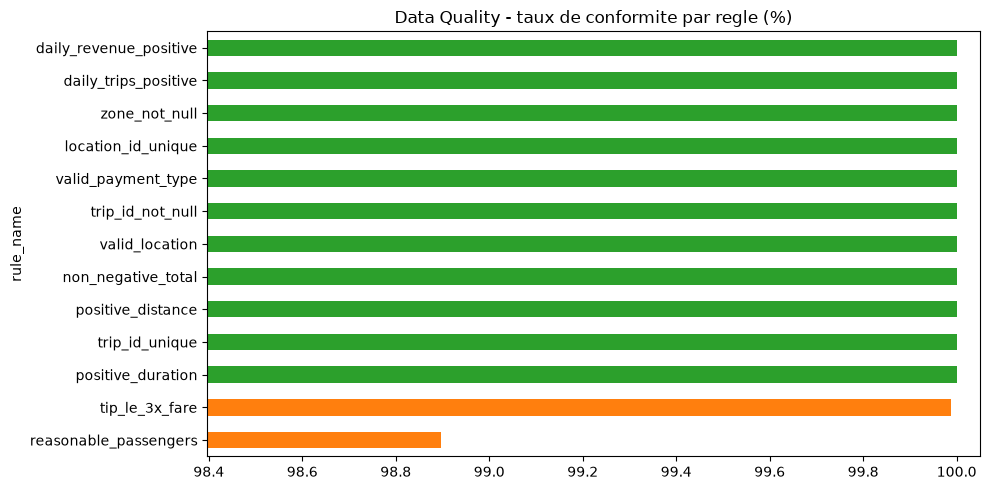

In [9]:
import matplotlib.pyplot as plt
rep = dq_results.toPandas().sort_values("pass_rate")
colors = ["tab:red" if (s != "PASS" and sev == "critical") else "tab:orange" if s != "PASS" else "tab:green"
          for s, sev in zip(rep.status, rep.severity)]
ax = rep.plot.barh(x="rule_name", y="pass_rate", color=colors, legend=False, figsize=(10, 5),
                   title="Data Quality - taux de conformite par regle (%)")
ax.set_xlim(rep.pass_rate.min() - 0.5, 100.05); plt.tight_layout(); plt.show()

## 4. Error Handling

1. **Table manquante / erreur SQL** → `run_dq_checks` ne plante pas: la règle reçoit le statut `ERROR: ...`.
2. **Règle critique en échec** → `assert_no_critical_failures` lève `DataQualityError` → dans un Job (Phase 9), la tâche échoue et **les tâches suivantes ne s'exécutent pas**.
3. **Toute erreur est journalisée** dans `ops.dq_results` (on garde la trace même en cas d'échec).

In [10]:
# Demo 1: table inexistante -> statut ERROR, pas de crash
bad_rules = [{"table": "workspace.silver.table_inexistante", "rule": "demo", "condition": "1 = 1", "severity": "critical"}]
run_dq_checks(spark, bad_rules, "demo").select("table_name", "rule_name", "status").show(truncate=60)

+----------------------------------+---------+------------------------------------------------------------+
|                        table_name|rule_name|                                                      status|
+----------------------------------+---------+------------------------------------------------------------+
|workspace.silver.table_inexistante|     demo|ERROR: [TABLE_OR_VIEW_NOT_FOUND] The table or view `works...|
+----------------------------------+---------+------------------------------------------------------------+



In [11]:
# Demo 2: regle critique volontairement fausse -> DataQualityError attrapee
demo_rules = [{"table": T_SILVER_TRIPS, "rule": "demo_distance_lt_5", "condition": "trip_distance < 5", "severity": "critical"}]
try:
    assert_no_critical_failures(run_dq_checks(spark, demo_rules, "demo"))
except DataQualityError as e:
    print("DataQualityError attrapee ->", e)

DataQualityError attrapee -> 1 regle(s) critical en echec: workspace.silver.yellow_trips.demo_distance_lt_5 (FAIL, 908729 lignes)


In [12]:
# Controle final du run reel: bloque le pipeline si une regle critique echoue
assert_no_critical_failures(dq_results)
print("Aucune regle critique en echec - les donnees peuvent etre publiees.")

Aucune regle critique en echec - les donnees peuvent etre publiees.


## Conclusion — Data Quality Framework

- **13 règles** (unicité, non-nullité, bornes, cohérence) sur Silver et Gold, avec sévérité `critical` / `warning`.
- **8 tests unitaires** valident la logique de transformation sur des cas connus.
- Résultats **historisés** dans `ops.dq_results` (un `run_id` par exécution) → suivi de la qualité dans le temps.
- **Gestion d'erreurs**: erreurs techniques journalisées sans crash, échec critique = `DataQualityError` qui arrête le pipeline.
- Les seules alertes restantes sont des **warnings** (ex: `passenger_count` à 0 ou > 6) → données utilisables, à surveiller.